In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df1 = pd.read_csv('Diwali Sales Data.csv',encoding_errors='ignore')

In [3]:
df1.head(10)

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.00,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,AndhraPradesh,Southern,Govt,Auto,3,23934.00,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.00,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.00,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.00,NaN,NaN
5,1000588,Joni,P00057942,M,26-35,28,1,Himachal Pradesh,Northern,Food Processing,Auto,1,23877.00,NaN,NaN
6,1001132,Balk,P00018042,F,18-25,25,1,Uttar Pradesh,Central,Lawyer,Auto,4,23841.00,NaN,NaN
7,1002092,Shivangi,P00273442,F,55+,61,0,Maharashtra,Western,IT Sector,Auto,1,NaN,NaN,NaN
8,1003224,Kushal,P00205642,M,26-35,35,0,Uttar Pradesh,Central,Govt,Auto,2,23809.00,NaN,NaN
9,1003650,Ginny,P00031142,F,26-35,26,1,AndhraPradesh,Southern,Media,Auto,4,23799.99,NaN,NaN


In [4]:
# DATA CLEANING ---

# Drop column with all Null items
df = df1.dropna(axis=1, how='all')

# Drop null raws in Amount
df = df.dropna(subset=['Amount'])

# Type conversion to int
df['Amount'] = df['Amount'].astype(int)

df.head(10)

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952
1,1000732,Kartik,P00110942,F,26-35,35,1,AndhraPradesh,Southern,Govt,Auto,3,23934
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877
5,1000588,Joni,P00057942,M,26-35,28,1,Himachal Pradesh,Northern,Food Processing,Auto,1,23877
6,1001132,Balk,P00018042,F,18-25,25,1,Uttar Pradesh,Central,Lawyer,Auto,4,23841
8,1003224,Kushal,P00205642,M,26-35,35,0,Uttar Pradesh,Central,Govt,Auto,2,23809
9,1003650,Ginny,P00031142,F,26-35,26,1,AndhraPradesh,Southern,Media,Auto,4,23799
10,1003829,Harshita,P00200842,M,26-35,34,0,Delhi,Central,Banking,Auto,1,23770


In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 11239 entries, 0 to 11250
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   User_ID           11239 non-null  int64
 1   Cust_name         11239 non-null  str  
 2   Product_ID        11239 non-null  str  
 3   Gender            11239 non-null  str  
 4   Age Group         11239 non-null  str  
 5   Age               11239 non-null  int64
 6   Marital_Status    11239 non-null  int64
 7   State             11239 non-null  str  
 8   Zone              11239 non-null  str  
 9   Occupation        11239 non-null  str  
 10  Product_Category  11239 non-null  str  
 11  Orders            11239 non-null  int64
 12  Amount            11239 non-null  int64
dtypes: int64(5), str(8)
memory usage: 1.2 MB


In [6]:
df.describe()

,User_ID,Age,Marital_Status,Orders,Amount
count,1.123900e+04,11239.000000,11239.000000,11239.000000,11239.000000
mean,1.003004e+06,35.410357,0.420055,2.489634,9453.610553
std,1.716039e+03,12.753866,0.493589,1.114967,5222.355168
min,1.000001e+06,12.000000,0.000000,1.000000,188.000000
25%,1.001492e+06,27.000000,0.000000,2.000000,5443.000000
50%,1.003064e+06,33.000000,0.000000,2.000000,8109.000000
75%,1.004426e+06,43.000000,1.000000,3.000000,12675.000000
max,1.006040e+06,92.000000,1.000000,4.000000,23952.000000


## Who buys more? (Gender Analysis)

In [7]:
genderwise_amount = df.groupby('Gender')['Amount'].sum()
print(genderwise_amount)

Gender
F    74335853
M    31913276
Name: Amount, dtype: int64


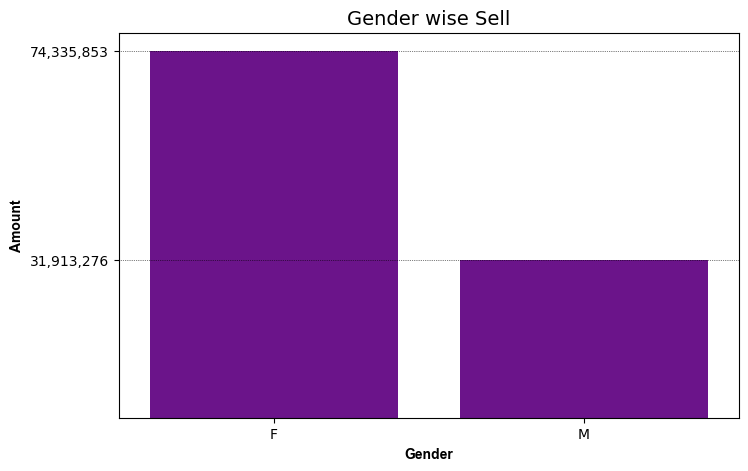

In [8]:
import matplotlib.ticker as ticker

# Create the plot
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=genderwise_amount.index, y=genderwise_amount.values, color='#74009E')

# FIX: Format Y-axis to show full numbers instead of 1e7
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x):,}'))

# Formatting
plt.title('Gender wise Sell', fontsize=14)
plt.xlabel('Gender', fontsize=10, family='Arial', fontweight='bold')
plt.ylabel('Amount', fontsize=10, family='Arial', fontweight='bold')

# Using the actual values for ticks as you requested
plt.yticks(genderwise_amount.values)

plt.grid(axis='y', linewidth=0.5, color='black', linestyle='dotted')

plt.show()


Conclusion : Females buy more than Males , here Amount of sell of female is morethan double than males.

## Which Age Group is our target?

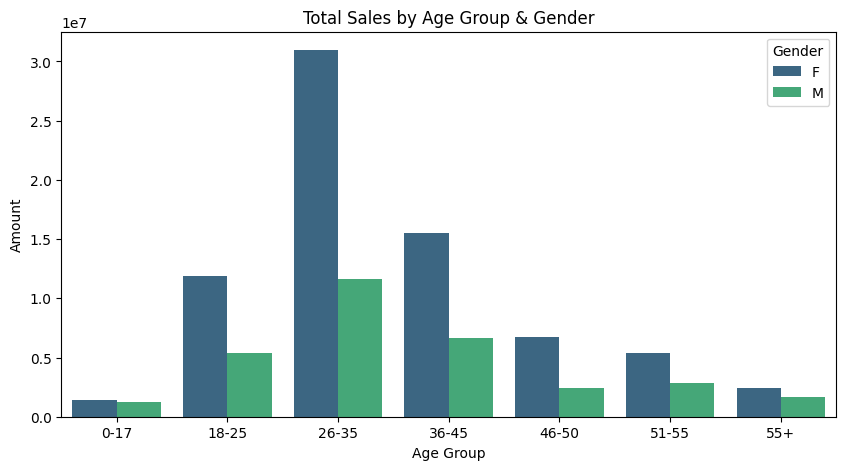

In [9]:
# Prevent scientific notation
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Grouping by Age Group and Gender to see Total Amount
age_gender_sales = df.groupby(['Age Group', 'Gender'], as_index=False)['Amount'].sum()

# Visual: Bar Chart with Hue
plt.figure(figsize=(10,5))
sns.barplot(x='Age Group', y='Amount', hue='Gender', data=age_gender_sales, palette='viridis')
plt.title('Total Sales by Age Group & Gender')
plt.show()

Conclusion : Females in age group of 26-35 buys most

## Top 10 States by Orders

C:\Users\sutha\AppData\Local\Temp\ipykernel_3044\3121084137.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Orders', y='State', data=state_orders, palette='magma')


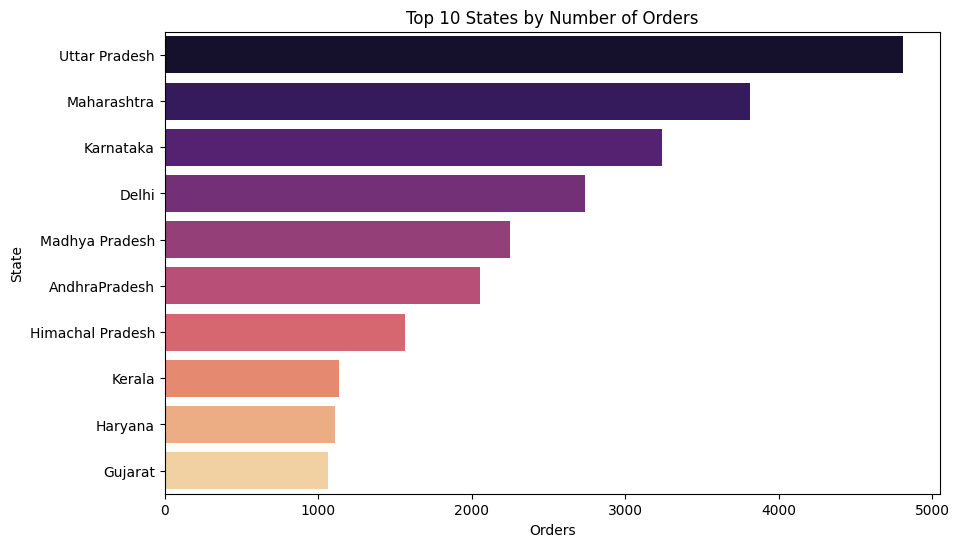

In [10]:
# Prevent scientific notation
pd.set_option('display.float_format', lambda x: '%.2f' % x)
#  Group by State and sum Orders
state_orders = df.groupby('State', as_index=False)['Orders'].sum().sort_values(by='Orders', ascending=False).head(10)

# Visual: Horizontal Bar Chart
plt.figure(figsize=(10,6))
sns.barplot(x='Orders', y='State', data=state_orders, palette='magma')
plt.title('Top 10 States by Number of Orders')
plt.show()

Uttar Pradesh, Maharashtra, and Karnataka are our top 3 markets

## Which products earn the most money?

C:\Users\sutha\AppData\Local\Temp\ipykernel_3044\2341153147.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Amount', y='Product_Category', data=product_sales, palette='coolwarm')


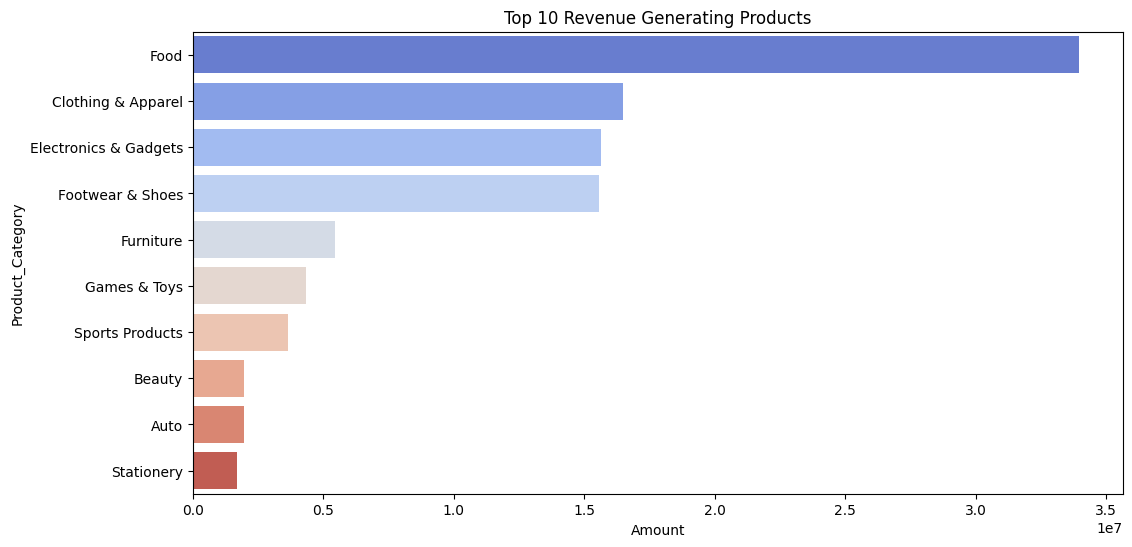

In [11]:
# Prevent scientific notation
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Group by Product_Category and sum Amount
product_sales = df.groupby('Product_Category', as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False).head(10)

# Visual
plt.figure(figsize=(12,6))
sns.barplot(x='Amount', y='Product_Category', data=product_sales, palette='coolwarm')
plt.title('Top 10 Revenue Generating Products')
plt.show()

Food, Clothing, and Electronics are the highest revenue drivers

## 